## Demo 05

# Model evaluation
<div class="alert alert-block alert-info">
    
<b>Note:</b> This notebook is a "cleaned-up" version of the code written in class; it contains only minimal textual explanation. Please refer to the lessons for further information about what is done, and why.
    
</div>

In [7]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

***

### Generate some toy regression-data

In [32]:
N_test, N_train = 30, 15

x_test = 2.0 * np.random.rand(N_test) - 1.0
X_test = np.vander(x_test, 9)
y_test = X_test[:, -2] + np.random.randn(N_test)

x_train = 2.0 * np.random.rand(N_train) - 1.0
X_train = np.vander(x_train, 9)
y_train = X_train[:, -2] + np.random.randn(N_train)

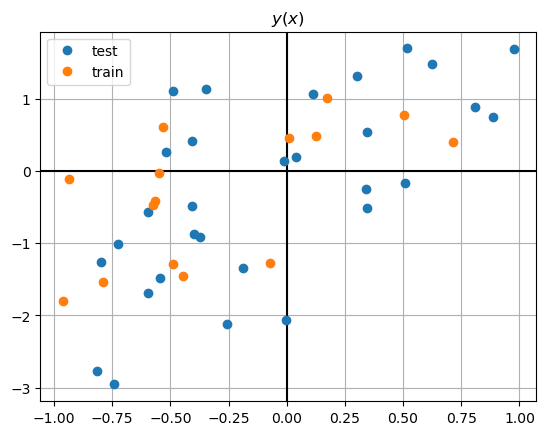

In [33]:
plt.grid(True); plt.axhline(0.0, c='k'); plt.axvline(0.0, c='k')
plt.plot(x_test, y_test, 'o', label='test')
plt.plot(x_train, y_train, 'o', label='train')
plt.legend()
plt.title('$y(x)$')
plt.show()

***

### Dummy-regressor

In [10]:
prediction = np.mean(y_train)
y_hat = np.full_like(y_test, prediction)

y_hat

array([-0.19357856, -0.19357856, -0.19357856, -0.19357856, -0.19357856,
       -0.19357856, -0.19357856, -0.19357856, -0.19357856, -0.19357856,
       -0.19357856, -0.19357856, -0.19357856, -0.19357856, -0.19357856,
       -0.19357856, -0.19357856, -0.19357856, -0.19357856, -0.19357856,
       -0.19357856, -0.19357856, -0.19357856, -0.19357856, -0.19357856,
       -0.19357856, -0.19357856, -0.19357856, -0.19357856, -0.19357856])

In [34]:
# https://scikit-learn.org/stable/developers/develop.html
# Note that some of this (in particular validate_data) needs a relatively new version of scikit-learn.
# If it gives you problems, you can always comment it out, and take care of your input data yourself.
# In particular, be aware that pandas dataframes and numpy arrays don't behave the same. C.f. df.to_numpy.

import sklearn.base
from sklearn.exceptions import NotFittedError
from sklearn.utils.estimator_checks import check_estimator
from sklearn.utils.validation import check_is_fitted, validate_data

# First the mixin, then the base estimator
class DummyRegressor(sklearn.base.RegressorMixin, sklearn.base.BaseEstimator):
    def __sklearn_tags__(self):
        # It checks whether our fitted model isn't complete garbage, but this one is.
        tags = super().__sklearn_tags__()
        tags.regressor_tags.poor_score = True
        return tags
        
    def fit(self, X, y):
        # validate_data makes sure that the shapes of x and y are sane, and sets some attributes on the estimator
        X, y = validate_data(self, X=X, y=y)
        # The trailing _ is how `check_is_fitted` knows that this estimator has been fit.
        self.is_fitted_ = True
        self.mean_ = np.mean(y)
        # API convention says that fit should return the fitted estimator.
        return self

    def predict(self, X):
        # Validate the data again, and makes sure that the shape (specifically, number of features) matches what was used in fitting
        X = validate_data(self, X=X, reset=False)
        # Also make sure that we are in fact already fitted, and raise an error otherwise
        check_is_fitted(self)
        return np.full(X.shape[0], self.mean_)

# Check whether this estimator conforms to the sklearn conventions.
check_estimator(DummyRegressor())


dummy_regressor = DummyRegressor()
dummy_regressor.fit(X_train, y_train)
y_hat = dummy_regressor.predict(X_test)
print(y_hat)

[-0.30645733 -0.30645733 -0.30645733 -0.30645733 -0.30645733 -0.30645733
 -0.30645733 -0.30645733 -0.30645733 -0.30645733 -0.30645733 -0.30645733
 -0.30645733 -0.30645733 -0.30645733 -0.30645733 -0.30645733 -0.30645733
 -0.30645733 -0.30645733 -0.30645733 -0.30645733 -0.30645733 -0.30645733
 -0.30645733 -0.30645733 -0.30645733 -0.30645733 -0.30645733 -0.30645733]


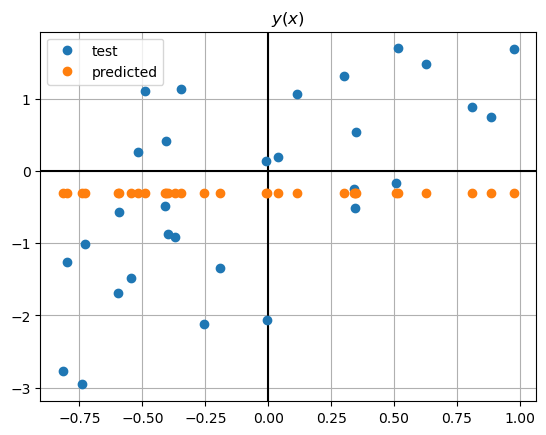

In [35]:
plt.grid(True); plt.axhline(0.0, c='k'); plt.axvline(0.0, c='k')
plt.plot(x_test, y_test, 'o', label='test')
plt.plot(x_test, y_hat, 'o', label='predicted')
plt.legend()
plt.title('$y(x)$')
plt.show()

***

### Scikit-learn

In [36]:
from sklearn.dummy import DummyRegressor

model = DummyRegressor()
model.fit(X_train, y_train)
y_hat = model.predict(X_test)

y_hat

array([-0.30645733, -0.30645733, -0.30645733, -0.30645733, -0.30645733,
       -0.30645733, -0.30645733, -0.30645733, -0.30645733, -0.30645733,
       -0.30645733, -0.30645733, -0.30645733, -0.30645733, -0.30645733,
       -0.30645733, -0.30645733, -0.30645733, -0.30645733, -0.30645733,
       -0.30645733, -0.30645733, -0.30645733, -0.30645733, -0.30645733,
       -0.30645733, -0.30645733, -0.30645733, -0.30645733, -0.30645733])

***

### Common regression evaluation metrics

Coefficient of determination

$$
R^2 = 1 - \frac{\sum_{i=1}^m \left( \hat{y}_i - y_i \right) ^ 2}{\sum_{i=1}^m \left( \bar{y} - y_i \right) ^ 2}
$$

Mean squared error

$$
\text{MSE} = \frac{1}{m} \sum_{i=1}^m \left( \hat{y}_i - y_i \right) ^ 2
$$

Median absolute error

$$
\text{MAE} = \text{med}_i \left\{ \left| \hat{y}_i - y_i \right| \right\}
$$

In [37]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
algorithms = {
    'Dummy-regressor': DummyRegressor,
    'Linear regression': LinearRegression,
    'Ridge regression': Ridge
}

from sklearn.metrics import r2_score, mean_squared_error, median_absolute_error
metrics = {
    'R²': r2_score,
    'MSE': mean_squared_error,
    'MAE': median_absolute_error
}

In [38]:
evaluation = pd.DataFrame()
for alg_name, alg_class in algorithms.items():
    model = alg_class()
    model.fit(X_train, y_train)
    y_hat = model.predict(X_test)
    evaluation[alg_name] = {met_name: met_func(y_test, y_hat) for met_name, met_func in metrics.items()}
    
evaluation.T

,R²,MSE,MAE
Dummy-regressor,-0.001410,1.684728,1.049255
Linear regression,-19080.916579,32102.580303,1.627431
Ridge regression,0.321766,1.141031,0.754869


***

### Generate some toy classification-data

In [40]:
from sklearn.datasets import make_blobs

N_test, N_train = [20, 30], [10, 15]

X_test, y_test = make_blobs(n_samples=N_test, n_features=2, centers=[[-1, -.5], [1, .5]])
X_train, y_train = make_blobs(n_samples=N_train, n_features=2, centers=[[-1, -.5], [1, .5]])

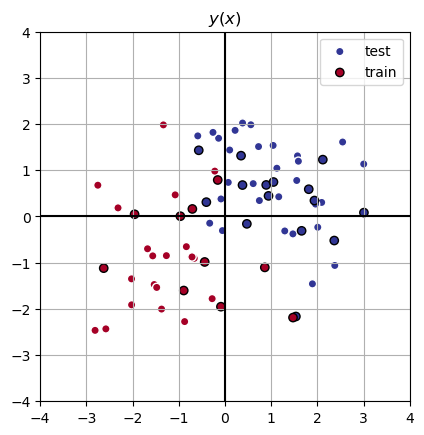

In [41]:
plt.grid(True); plt.axhline(0.0, c='k'); plt.axvline(0.0, c='k')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='RdYlBu', edgecolors='w', label='test')
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='RdYlBu', edgecolors='k', label='train')
plt.legend()
plt.title('$y(x)$')
plt.axis('square'); plt.axis((-4.0, 4.0, -4.0, 4.0))
plt.show()

***

### Dummy-classifier

In [42]:
prediction = np.mean(y_train == 1)
y_proba = np.full_like(y_test, prediction, dtype=float)

y_proba

array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6,
       0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6,
       0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6,
       0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

In [43]:
y_hat = (y_proba > 0.5).astype(int)

y_hat

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1])

In [44]:
from sklearn.utils.multiclass import unique_labels


class DummyClassifier(sklearn.base.ClassifierMixin, sklearn.base.BaseEstimator):
    def __sklearn_tags__(self):
        # It checks whether our fitted model isn't complete garbage, but this one is.
        tags = super().__sklearn_tags__()
        tags.classifier_tags.poor_score = True
        return tags

    def fit(self, X, y):
        X, y = validate_data(self, X, y)
        self.classes_ = unique_labels(y)
        self.is_fitted_ = True
        onehot = y[:, np.newaxis] == self.classes_[np.newaxis]
        self.likelihoods_ = np.mean(onehot, axis=0)
        return self

    def predict_proba(self, X):
        X = validate_data(self, X, reset=False)
        check_is_fitted(self)
        return np.full((X.shape[0], self.classes_.shape[0]), self.likelihoods_[np.newaxis, :])

    def predict(self, X):
        probas = self.predict_proba(X)
        idxs = np.argmax(probas, axis=1)
        return self.classes_[idxs]

check_estimator(DummyClassifier())

clf = DummyClassifier()
clf.fit(X_train, y_train)
proba = clf.predict_proba(X_test)
labels = clf.predict(X_test)

print(proba)
print(labels)

[[0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]
 [0.4 0.6]]
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1]


/tmp/ipykernel_802266/1976630585.py:7: UserWarning: No contour levels were found within the data range.
  plt.contour(xx1, xx2, yy, [0.5], linewidths=0.5, linestyles='dashed')


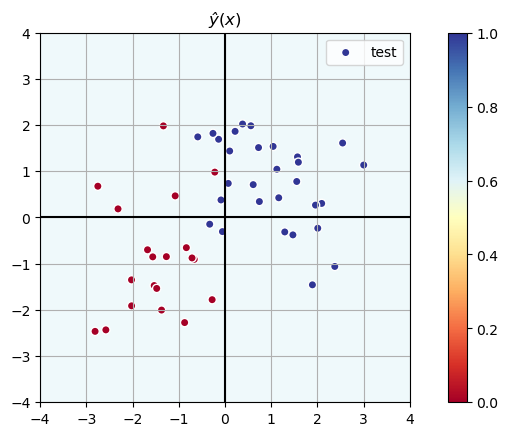

In [45]:
xx1, xx2 = np.meshgrid(np.linspace(-4.0, 4.0, 81), np.linspace(-4.0, 4.0, 81))
XX = np.array([xx1.ravel(), xx2.ravel(), np.ones(xx1.size)]).T
yy = np.full_like(xx1, prediction)

plt.grid(True); plt.axhline(0.0, c='k'); plt.axvline(0.0, c='k')
plt.imshow(yy, extent=(-4.0, 4.0, -4.0, 4.0), origin='lower', interpolation='bilinear', cmap='RdYlBu', vmin=0.0, vmax=1.0, alpha=0.5)
plt.contour(xx1, xx2, yy, [0.5], linewidths=0.5, linestyles='dashed')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='RdYlBu', edgecolors='w', label='test')
plt.colorbar()
plt.legend()
plt.title('$ŷ(x)$')
plt.axis('square'); plt.axis((-4.0, 4.0, -4.0, 4.0))
plt.show()

***

### Scikit-learn

In [22]:
from sklearn.dummy import DummyClassifier

model = DummyClassifier()
model.fit(X_train, y_train)

y_proba = model.predict_proba(X_test)

y_proba

array([[0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.4, 0.6]])

In [23]:
y_hat = model.predict(X_test)

y_hat

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1])

***

### Common classification evaluation metrics

Accuracy

$$
\text{ACC} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}
$$

Precision

$$
\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}
$$

Recall

$$
\text{Recall} = \frac{\text{TP}} {\text{TP} + \text{FN}}
$$

F1-score

$$
\text{F1} = \frac{2 \cdot \text{Precision} \cdot \text{Recall} } {\text{Precision} + \text{Recall}}= \frac{2 \cdot \text{TP}}{2 \cdot \text{TP} + \text{FP} + \text{FN}}
$$

Area Under the Receiver Operating Characteristic (ROC) Curve

$$
\text{AUC} = \int_0^1 \text{TPR} \, \text{d} \, \text{FPR}
$$

In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
algorithms = {
    'Dummy-classifier': DummyClassifier,
    'Logistic regression': LogisticRegression,
    'Gaussian Naive Bayes': GaussianNB
}

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
metrics = {
    'ACC': accuracy_score,
    'F1': f1_score,
    'AUC': roc_auc_score
}

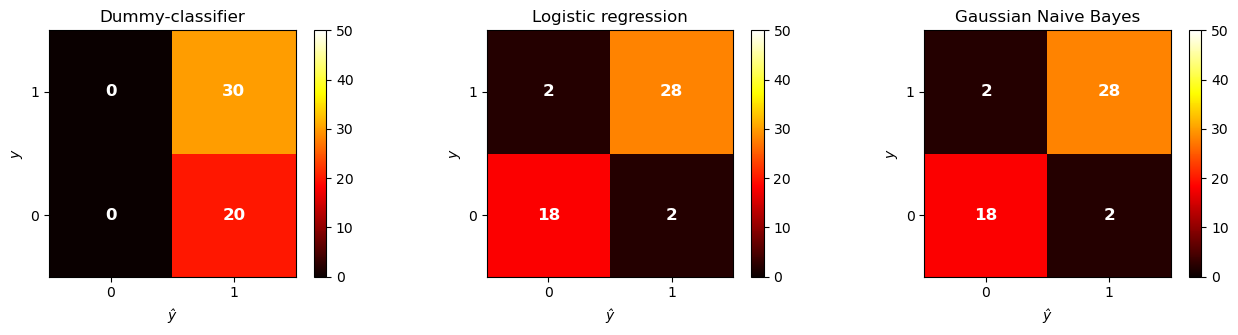

In [48]:
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(16.0, 3.2))
for index, (alg_name, alg_class) in enumerate(algorithms.items()):
    model = alg_class()
    model.fit(X_train, y_train)
    y_hat = model.predict(X_test)
    plt.subplot(1, len(algorithms), index + 1)
    plt.imshow(confusion_matrix(y_test, y_hat), origin='lower', cmap='hot', vmin=0, vmax=len(y_test))
    for hori in range(2):
        for vert in range(2):
            plt.text(hori, vert, f'{np.sum(np.logical_and(y_hat == hori, y_test == vert))}', c='w', size='large', weight='bold', ha='center', va='center')
    plt.colorbar()
    plt.xticks((0, 1)); plt.yticks((0, 1))
    plt.xlabel('$ŷ$'); plt.ylabel('$y$')
    plt.title(alg_name)
plt.show()

In [49]:
from sklearn.metrics import classification_report

for alg_name, alg_class in algorithms.items():
    model = alg_class()
    model.fit(X_train, y_train)
    y_hat = model.predict(X_test)
    print(alg_name.upper().center(53, '='))
    print(classification_report(y_test, y_hat, digits=3, zero_division=np.nan))   

===================DUMMY-CLASSIFIER==================
              precision    recall  f1-score   support

           0        nan     0.000     0.000        20
           1      0.600     1.000     0.750        30

    accuracy                          0.600        50
   macro avg      0.600     0.500     0.375        50
weighted avg      0.600     0.600     0.450        50

=================LOGISTIC REGRESSION=================
              precision    recall  f1-score   support

           0      0.900     0.900     0.900        20
           1      0.933     0.933     0.933        30

    accuracy                          0.920        50
   macro avg      0.917     0.917     0.917        50
weighted avg      0.920     0.920     0.920        50

=================GAUSSIAN NAIVE BAYES================
              precision    recall  f1-score   support

           0      0.900     0.900     0.900        20
           1      0.933     0.933     0.933        30

    accuracy        

In [47]:
evaluation = pd.DataFrame()
for alg_name, alg_class in algorithms.items():
    model = alg_class()
    model.fit(X_train, y_train)
    y_proba = model.predict_proba(X_test)
    y_hat = model.predict(X_test)
    evaluation[alg_name] = {met_name: met_func(y_test, y_proba[:, 1]) if met_name == 'ROC' else met_func(y_test, y_hat) for met_name, met_func in metrics.items()}
    
evaluation.T

,ACC,F1,AUC
Dummy-classifier,0.60,0.750000,0.500000
Logistic regression,0.92,0.933333,0.916667
Gaussian Naive Bayes,0.92,0.933333,0.916667


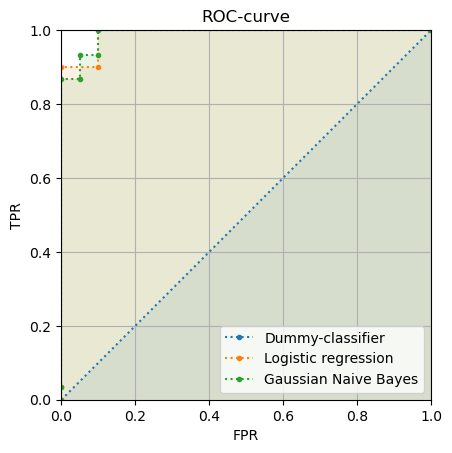

In [50]:
from sklearn.metrics import roc_curve

for alg_name, alg_class in algorithms.items():
    model = alg_class()
    model.fit(X_train, y_train)
    y_proba = model.predict_proba(X_test)
    fpr, tpr, _ = roc_curve(y_test, y_proba[:, 1])
    plt.plot(fpr, tpr, '.:', label=alg_name)
    plt.fill_between(fpr, tpr, alpha=0.1)
plt.grid(True)
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC-curve')
plt.axis('square'); plt.axis((0.0, 1.0, 0.0, 1.0))
plt.legend()
plt.show()

***

&copy; 2024 - Dave R.M. Langers <d.r.m.langers@pl.hanze.nl>